# Memory, similarity, and search
**CS 301 · Unit III · Meeting 3 (course meeting 23)**

A database key can identify a record exactly. A noisy audio fragment and a word
meaning do not arrive with the identifier of the desired answer. We need a
representation, a comparison rule, and a way to search stored information.

This notebook follows the lecture: content retrieval, word vectors, k-nearest
neighbors, non-parametric learning, kd-tree construction and exact search, then
the cost of searching in more dimensions. Run the cells in order. All main-route
data are embedded or generated here, so no account, dataset download, microphone,
or GPU is required. The notebook contains executed results as an example run.
Rerunning the timing cells will give different times on different machines.

In class, predict the outcome before changing a setting. Computing is optional:
the figures and printed results can also be read and discussed directly.

In [1]:
import base64, json, zlib, platform, time
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, KDTree
from sklearn.metrics import accuracy_score, mean_squared_error
from threadpoolctl import threadpool_limits
from IPython.display import display, Audio

SEED = 23
KS = [1, 3, 5, 11, 21, 41]
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':0.18})
BLUE, RUST, GREEN, GOLD = '#286bab', '#c5473a', '#087f6d', '#986000'
print('Python', platform.python_version(), '| NumPy', np.__version__, '| scikit-learn', sklearn.__version__)

Python 3.12.10 | NumPy 2.5.4 | scikit-learn 1.9.1


## 1. An observation as a query

Shazam identifies a recording from a captured fragment. Its classic published
algorithm uses local audio fingerprints, looks up matching fingerprint tokens,
then checks whether many matches imply the same time offset. Exact local lookup
can therefore contribute to identifying an imperfect observation of a recording.

The small experiment below demonstrates that combination. Three synthetic tone
sequences form a catalog. We take an excerpt of sequence B and add noise. A toy
fingerprint is a pair of dominant frequency bins in consecutive frames.
Here a **frame** is a short window of sound, and a **frequency bin** is a small
frequency interval in its spectrum. The dominant bin contains the strongest
spectral component in that frame.

**Scope:** this is a deliberately simplified illustration, not an implementation
of Shazam. The crop is aligned with the analysis frame grid. Arbitrary shifts,
recording distortions, and a large music catalog require a more capable design.
No neural model is trained in this experiment.

In [2]:
def make_audio_catalog(fs=8000, seconds=8):
    """Synthetic tone sequences; no copyrighted recording or trained encoder."""
    rng=np.random.default_rng(SEED)
    notes=np.array([220,277.18,329.63,392,440,523.25,659.25,783.99])
    t=np.arange(int(fs*seconds))/fs
    catalog={}
    for name in ['A','B','C']:
        freqs=rng.choice(notes,size=16,replace=True)
        freq=freqs[np.minimum((t/0.5).astype(int),15)]
        phase=2*np.pi*np.cumsum(freq)/fs
        # Smooth onset within each note avoids clicks dominating the spectrum.
        within=(t%0.5)/0.5
        envelope=np.minimum(1,within/0.05)*np.minimum(1,(1-within)/0.05)
        catalog[name]=envelope*(0.65*np.sin(phase)+0.2*np.sin(2*phase))
    return fs,catalog


def audio_fingerprint(signal, fs=8000):
    """Toy fingerprints: adjacent-frame dominant-frequency-bin pairs.

    This intentionally small construction is NOT Shazam's landmark algorithm.
    The frame grid assumes an aligned crop; arbitrary shifts need more work.
    """
    frame=512; hop=256
    window=np.hanning(frame)
    peaks=[]
    for start in range(0,len(signal)-frame+1,hop):
        spectrum=np.abs(np.fft.rfft(signal[start:start+frame]*window))
        spectrum[:6]=0
        peaks.append(int(np.argmax(spectrum)))
    return [((peaks[i],peaks[i+1]), i) for i in range(len(peaks)-1)], peaks


def retrieve_audio(catalog, query, fs=8000):
    index=defaultdict(list)
    references={}
    for name,signal in catalog.items():
        tokens,peaks=audio_fingerprint(signal,fs)
        references[name]=dict(tokens=[[list(token),t] for token,t in tokens],peaks=peaks)
        for token,t in tokens:index[token].append((name,t))
    query_tokens,query_peaks=audio_fingerprint(query,fs)
    votes=Counter()
    for token,t in query_tokens:
        for name,reference_t in index.get(token,[]):votes[(name,reference_t-t)]+=1
    ranking=[]
    for name in sorted(catalog):
        offsets=[(count,offset) for (track,offset),count in votes.items() if track==name]
        count,offset=max(offsets,default=(0,0))
        ranking.append(dict(track=name,votes=count,offset_frames=offset,offset_seconds=offset*256/fs))
    ranking.sort(key=lambda a:(-a['votes'],a['track']))
    return dict(references=references,query_peaks=query_peaks,
                query_tokens=[[list(token),t] for token,t in query_tokens], ranking=ranking,
                offset_votes={name:[dict(offset_frames=offset,votes=count) for (track,offset),count in sorted(votes.items()) if track==name] for name in catalog})

In [3]:
fs, audio_catalog = make_audio_catalog()
start, length = 64*256, 96*256
clean_query = audio_catalog['B'][start:start+length]
audio_rng = np.random.default_rng(SEED+7)
audio_query = clean_query + 0.12*audio_rng.normal(size=len(clean_query))
audio_result = retrieve_audio(audio_catalog, audio_query, fs)
print('Noisy query:')
display(Audio(audio_query, rate=fs))
print('Best consistent offset for each catalog item:')
for row in audio_result['ranking']:
    print(f"{row['track']}: {row['votes']:3d} votes, offset {row['offset_seconds']:.3f} seconds")
assert audio_result['ranking'][0]['track'] == 'B'
assert audio_result['ranking'][0]['offset_frames'] == 64

Noisy query:


Best consistent offset for each catalog item:
B:  83 votes, offset 2.048 seconds
A:  49 votes, offset 0.544 seconds
C:  29 votes, offset -0.448 seconds


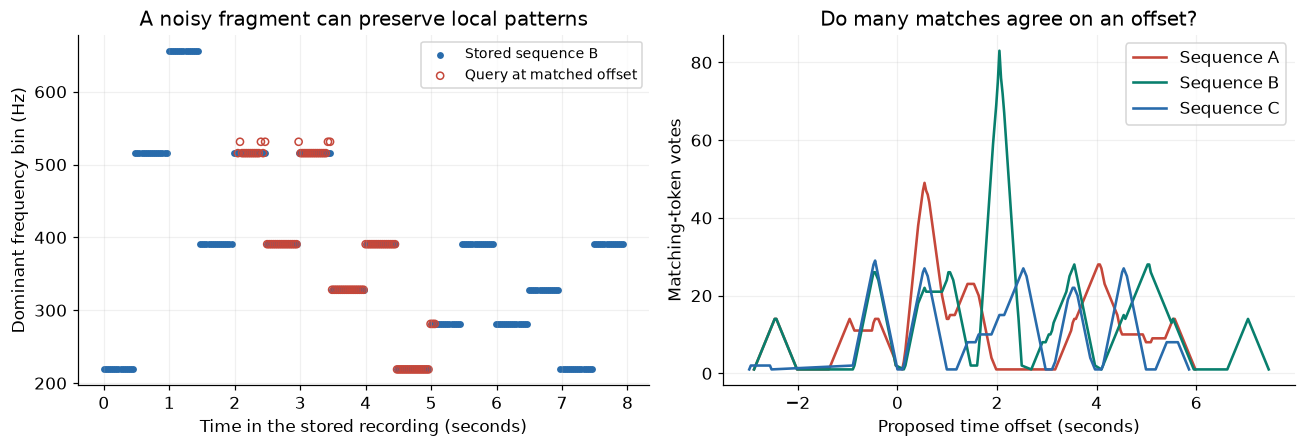

In [4]:
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
reference_peaks = np.array(audio_result['references']['B']['peaks'])
query_peaks = np.array(audio_result['query_peaks'])
axes[0].scatter(np.arange(len(reference_peaks))*256/fs, reference_peaks*fs/512,
                s=12, color=BLUE, label='Stored sequence B')
axes[0].scatter(np.arange(len(query_peaks))*256/fs+start/fs, query_peaks*fs/512,
                s=22, facecolors='none', edgecolors=RUST, label='Query at matched offset')
axes[0].set(xlabel='Time in the stored recording (seconds)', ylabel='Dominant frequency bin (Hz)',
            title='A noisy fragment can preserve local patterns')
axes[0].legend(fontsize=9)
for track,color in zip(['A','B','C'],[RUST,GREEN,BLUE]):
    rows=audio_result['offset_votes'][track]
    axes[1].plot([r['offset_frames']*256/fs for r in rows], [r['votes'] for r in rows],
                 label='Sequence '+track,color=color,linewidth=1.7)
axes[1].set(xlabel='Proposed time offset (seconds)',ylabel='Matching-token votes',
            title='Do many matches agree on an offset?')
axes[1].legend()
fig.tight_layout(); plt.show()

**Think before changing the code:** what happens if the correct sequence is
removed from `audio_catalog`? An algorithm can still return the highest score,
but a highest score alone does not establish a trustworthy match. A deployed
system needs an acceptance rule, evaluated on matching and non-matching queries.

**A related approach:** neural audio fingerprinting can learn a vector for each
short audio segment, then search stored vectors by similarity. This connects to
word embeddings: a learned representation and a retrieval algorithm can work
together. The neural encoder has learned parameters; its searchable catalog can
grow independently. See [Chang et al., ICASSP 2021](https://arxiv.org/abs/2010.11910).

## 2. Revisit the word vectors

In Unit II, `U @ v` compared a query with every one of 50,000 word vectors. Each
row of `U` had been divided by its length, so a dot product was cosine similarity.

This notebook embeds **125 real GloVe word vectors** at both 50 and 300 dimensions,
selected from those same course files. We search this smaller candidate catalog
to keep the notebook self-contained. The lecture's full-catalog neighbor lists
were computed separately over all 50,000 words. Results for an arbitrary query
in this small catalog need not equal the full-catalog results.

The following data cell contains compressed numeric data, not model-training
code. You can leave it collapsed and focus on the search cell that follows it.

In [5]:
EMBEDDED_WORD_DATA = '...'
word_data = json.loads(zlib.decompress(base64.b64decode(EMBEDDED_WORD_DATA)))
words = word_data['words']
word_position = {word:i for i,word in enumerate(words)}
print(len(words), 'stored word vectors; dimensions 50 and 300')

125 stored word vectors; dimensions 50 and 300


In [6]:
DIMENSION = 50                  # Try 50 or 300.
QUERY_WORD = 'python'            # Also try piano, bank, river, music, king, computer.
N_NEIGHBORS = 8
word_vectors = np.array(word_data['vectors'+str(DIMENSION)], dtype=np.float32)
word_lengths = np.linalg.norm(word_vectors, axis=1, keepdims=True)
assert np.all(word_lengths > 0)
U = word_vectors / word_lengths

def nearest_words(query_word, count=8):
    query_index = word_position[query_word]
    similarity = U @ U[query_index]        # Compare with every stored vector.
    similarity[query_index] = -np.inf      # Exclude the word itself.
    indices = np.argsort(-similarity, kind='stable')[:count]
    return [(words[i], float(similarity[i])) for i in indices]

print(f'Nearest words to {QUERY_WORD!r} among {len(words)} candidates, {DIMENSION} dimensions:')
for word, score in nearest_words(QUERY_WORD, N_NEIGHBORS):
    print(f'{word:16s} {score:.4f}')

Nearest words to 'python' among 125 candidates, 50 dimensions:
php              0.6415
owl              0.6301
mouse            0.6276
perl             0.6268
monkey           0.6208
monty            0.6079
scripting        0.6042
rhino            0.5956


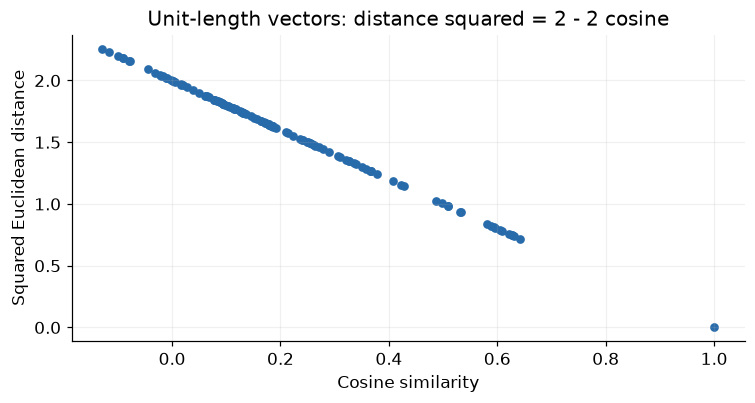

In [7]:
query_index = word_position[QUERY_WORD]
cosines = U @ U[query_index]
distances_squared = np.sum((U-U[query_index])**2, axis=1)
assert np.allclose(distances_squared, 2-2*cosines, atol=1e-6)
fig, ax = plt.subplots(figsize=(7,3.8))
ax.scatter(cosines, distances_squared, s=22, color=BLUE)
ax.set(xlabel='Cosine similarity',ylabel='Squared Euclidean distance',
       title='Unit-length vectors: distance squared = 2 - 2 cosine')
fig.tight_layout(); plt.show()

For unit vectors, maximizing cosine similarity and minimizing Euclidean distance
give the same ordering. Normalizing each vector is different from standardizing
each coordinate across the dataset. Changing embedding-coordinate scales changes
the geometry of the representation, so we do not do it automatically.

**Exercise:** compare the neighbors of `bank` at 50 and 300 dimensions. Which
meanings appear? A word's nearest neighbors describe patterns in the training
text, not an authoritative dictionary definition. Neither more coordinates nor
a larger similarity score guarantees that a result is useful for every task.

## 3. The units can change the neighbors

Distance combines coordinate differences. If one feature's numeric scale is much
larger than another's, it can dominate the answer. Here the same six rows are
searched in raw coordinates and after standardization.

The standardizer learns its means and standard deviations **from the training
rows only**. Both stored rows and future queries receive that same transformation.

In [8]:
def scaling_experiment():
    # Training data only determine the two column scales.
    X = np.array([[1, 100], [2, 300], [4, 105], [5, 500], [7, 700], [9, 900]], dtype=float)
    query = np.array([1.5, 110.0])
    scaler = StandardScaler().fit(X)
    raw = np.linalg.norm(X-query, axis=1)
    scaled = np.linalg.norm(scaler.transform(X)-scaler.transform(query[None, :]), axis=1)
    # Query chosen to expose a genuine changed ordering, rather than claim one.
    return dict(X=X.tolist(), y=['A','B','C','D','E','F'], query=query.tolist(),
                feature_names=['feature 1', 'feature 2'],
                raw_distances=raw.tolist(), scaled_distances=scaled.tolist(),
                raw_order=np.argsort(raw).tolist(), scaled_order=np.argsort(scaled).tolist(),
                mean=scaler.mean_.tolist(), scale=scaler.scale_.tolist())

raw [('C', 5.59), ('A', 10.012), ('B', 190.001)]
scaled [('A', 0.185), ('B', 0.665), ('C', 0.91)]


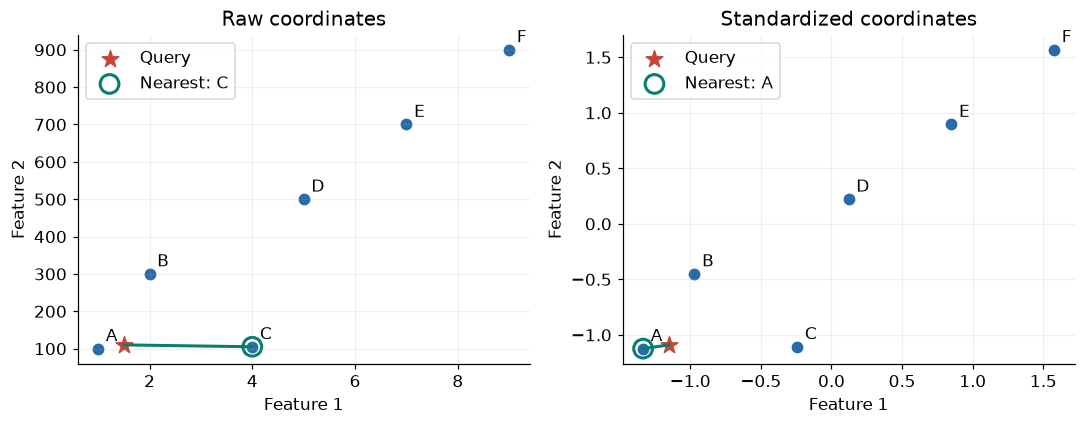

In [9]:
scale_demo = scaling_experiment()
for kind in ['raw','scaled']:
    print(kind, [(scale_demo['y'][i], round(scale_demo[kind+'_distances'][i],3))
                 for i in scale_demo[kind+'_order'][:3]])
fig,axes=plt.subplots(1,2,figsize=(10,4))
SX=np.array(scale_demo['X']); SQ=np.array(scale_demo['query'])
scaler=StandardScaler().fit(SX)
for ax,points,query,title in [
    (axes[0],SX,SQ,'Raw coordinates'),
    (axes[1],scaler.transform(SX),scaler.transform(SQ[None,:])[0],'Standardized coordinates')]:
    ax.scatter(points[:,0],points[:,1],c=BLUE,s=45)
    ax.scatter(*query,c=RUST,marker='*',s=130,label='Query')
    nearest=int(np.argmin(np.linalg.norm(points-query,axis=1)))
    ax.plot([query[0],points[nearest,0]],[query[1],points[nearest,1]],color=GREEN,linewidth=2)
    ax.scatter(*points[nearest],facecolors='none',edgecolors=GREEN,s=150,linewidths=2,
               label='Nearest: '+scale_demo['y'][nearest])
    for label,point in zip(scale_demo['y'],points): ax.annotate(label,point,xytext=(5,5),textcoords='offset points')
    ax.set(title=title,xlabel='Feature 1',ylabel='Feature 2'); ax.legend()
fig.tight_layout();plt.show()

The raw nearest point is C; after standardization it is A. Standardization is a
modeling choice, not a proof that A is the right answer. We need to decide what
the measurements mean and evaluate the resulting predictions. Each plot uses
separate horizontal and vertical axis scales; the printed numeric distances,
rather than apparent screen lengths, determine its selected neighbor.

## 4. Retrieved examples can make a prediction

A search result is a list of examples. A **k-nearest-neighbor predictor** adds a
rule for using them: vote among their labels for classification, or average their
values for regression. The input `X` contains the features; `y` supplies the
training labels or values; the output is a prediction, usually written y-hat.

We use synthetic examples so the geometry remains visible. The classification
data have 240 training rows and 120 validation rows. Another 120 rows remain
reserved. We do not use their labels or report their score. Validation selects
among the six stated values of k; it does not become part of the stored training
set during that comparison.

In [10]:
def classification_experiment():
    X, y = make_moons(n_samples=480, noise=0.25, random_state=SEED)
    development, reserved = train_test_split(np.arange(len(X)), test_size=0.25,
                                             stratify=y, random_state=SEED)
    train, valid = train_test_split(development, test_size=1/3,
                                   stratify=y[development], random_state=SEED+1)
    scaler = StandardScaler().fit(X[train])
    Xtrain, Xvalid = scaler.transform(X[train]), scaler.transform(X[valid])
    gx, gy = np.linspace(-1.7, 2.7, 64), np.linspace(-1.2, 1.7, 44)
    xx, yy = np.meshgrid(gx, gy)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    snapshots = []
    for k in KS:
        model = KNeighborsClassifier(n_neighbors=k, algorithm='brute').fit(Xtrain, y[train])
        snapshots.append(dict(k=k,
            train_accuracy=float(accuracy_score(y[train], model.predict(Xtrain))),
            valid_accuracy=float(accuracy_score(y[valid], model.predict(Xvalid))),
            prediction=model.predict(scaler.transform(grid)).tolist()))
    best = max(snapshots, key=lambda a: (a['valid_accuracy'], -a['k']))
    assert snapshots[0]['train_accuracy'] == 1
    assert len(set(train) & set(valid)) == 0 and len(set(train) & set(reserved)) == 0
    return dict(train=dict(X=X[train].tolist(), y=y[train].tolist()),
                valid=dict(X=X[valid].tolist(), y=y[valid].tolist()), test_n=len(reserved),
                grid=dict(x=gx.tolist(), y=gy.tolist(), shape=[len(gy), len(gx)]),
                snapshots=snapshots, selected_k=best['k'],
                selection='Highest validation accuracy; smallest k breaks a tie.',
                preprocessing=dict(mean=scaler.mean_.tolist(), scale=scaler.scale_.tolist()))

In [11]:
with threadpool_limits(limits=1):
    classification = classification_experiment()
print('  k   training accuracy   validation accuracy')
for row in classification['snapshots']:
    print(f"{row['k']:3d}        {row['train_accuracy']:6.2%}             {row['valid_accuracy']:6.2%}")
print('Selected k:',classification['selected_k'], '(highest validation accuracy; smaller k breaks a tie)')

  k   training accuracy   validation accuracy
  1        100.00%             92.50%
  3        95.42%             93.33%
  5        96.67%             92.50%
 11        96.25%             91.67%
 21        95.42%             92.50%
 41        93.33%             90.83%
Selected k: 3 (highest validation accuracy; smaller k breaks a tie)


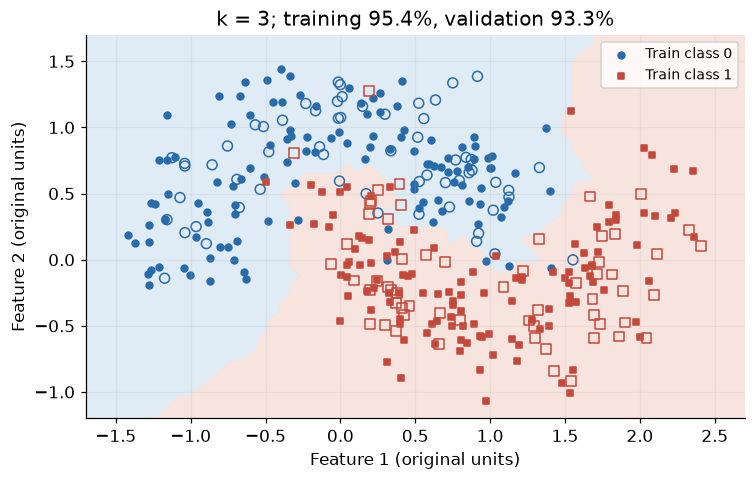

In [12]:
K = 3                            # Choose from KS and rerun this figure.
row = next(r for r in classification['snapshots'] if r['k']==K)
train_X=np.array(classification['train']['X']); train_y=np.array(classification['train']['y'])
valid_X=np.array(classification['valid']['X']); valid_y=np.array(classification['valid']['y'])
gx,gy=classification['grid']['x'],classification['grid']['y']
fig,ax=plt.subplots(figsize=(7,4.5))
ax.contourf(gx,gy,np.array(row['prediction']).reshape(classification['grid']['shape']),
             levels=[-.5,.5,1.5],colors=['#dce9f4','#f8e1db'],alpha=.9)
for label,color,marker in [(0,BLUE,'o'),(1,RUST,'s')]:
    ax.scatter(*train_X[train_y==label].T,c=color,marker=marker,s=20,label=f'Train class {label}')
    ax.scatter(*valid_X[valid_y==label].T,facecolors='none',edgecolors=color,marker=marker,s=42)
ax.set(xlabel='Feature 1 (original units)',ylabel='Feature 2 (original units)',
       title=f'k = {K}; training {row["train_accuracy"]:.1%}, validation {row["valid_accuracy"]:.1%}')
ax.legend(fontsize=9); fig.tight_layout();plt.show()

Filled markers are training examples; outlined markers are validation examples.
Prediction distances use standardized coordinates, although the axes above show
the original coordinates. A grid location gets the class predicted there.

**Reflection:** with k = 1, each distinct training input finds itself at distance
zero. Why does perfect training accuracy tell us little about a new input?

<details><summary>Instructor reference</summary>
The model can recover stored labels without establishing that nearby new
observations share those labels. Validation is the check. Here k = 3 has the
highest validation accuracy among the six choices, while k = 1 has perfect
training accuracy. This ranking is a result of one specified experiment, not a
universal rule about k.
</details>

In [13]:
def regression_experiment():
    rng = np.random.default_rng(SEED)
    X = rng.uniform(-2.5, 2.5, (180, 1))
    y = np.sin(2*X[:, 0]) + rng.normal(0, 0.3, len(X))
    order = rng.permutation(len(X))
    train, valid, reserved = order[:90], order[90:135], order[135:]
    grid = np.linspace(-2.5, 2.5, 201)
    snapshots = []
    for k in KS:
        model = KNeighborsRegressor(n_neighbors=k, algorithm='brute').fit(X[train], y[train])
        snapshots.append(dict(k=k,
            train_mse=float(mean_squared_error(y[train], model.predict(X[train]))),
            valid_mse=float(mean_squared_error(y[valid], model.predict(X[valid]))),
            prediction=model.predict(grid[:, None]).tolist()))
    weighted = KNeighborsRegressor(n_neighbors=11, weights='distance', algorithm='brute').fit(X[train], y[train])
    best = min(snapshots, key=lambda a: (a['valid_mse'], a['k']))
    return dict(train=dict(X=X[train, 0].tolist(), y=y[train].tolist()),
                valid=dict(X=X[valid, 0].tolist(), y=y[valid].tolist()), test_n=len(reserved),
                grid=grid.tolist(), signal=np.sin(2*grid).tolist(), snapshots=snapshots,
                selected_k=best['k'], baseline_valid_mse=float(np.mean((y[valid]-y[train].mean())**2)),
                weighted=dict(k=11, prediction=weighted.predict(grid[:, None]).tolist(),
                              valid_mse=float(mean_squared_error(y[valid], weighted.predict(X[valid])))))

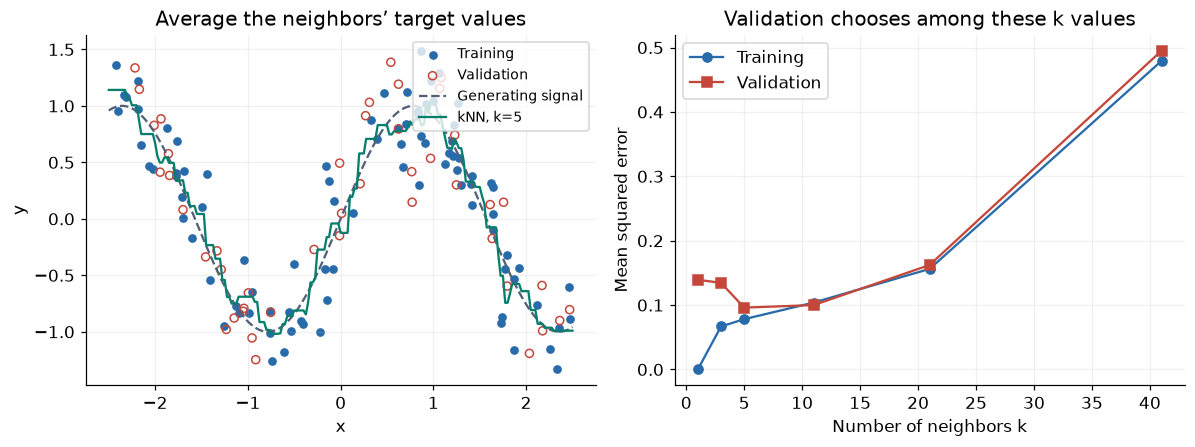

Selected k: 5
Reserved test rows: 45 (not scored)


In [14]:
with threadpool_limits(limits=1): regression=regression_experiment()
K=5
row=next(r for r in regression['snapshots'] if r['k']==K)
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
axes[0].scatter(regression['train']['X'],regression['train']['y'],s=22,c=BLUE,label='Training')
axes[0].scatter(regression['valid']['X'],regression['valid']['y'],s=28,facecolors='none',edgecolors=RUST,label='Validation')
axes[0].plot(regression['grid'],regression['signal'],'--',color='#526078',label='Generating signal')
axes[0].plot(regression['grid'],row['prediction'],color=GREEN,label=f'kNN, k={K}')
axes[0].set(xlabel='x',ylabel='y',title='Average the neighbors’ target values');axes[0].legend(fontsize=9)
rows=regression['snapshots']
axes[1].plot([r['k'] for r in rows],[r['train_mse'] for r in rows],'o-',color=BLUE,label='Training')
axes[1].plot([r['k'] for r in rows],[r['valid_mse'] for r in rows],'s-',color=RUST,label='Validation')
axes[1].set(xlabel='Number of neighbors k',ylabel='Mean squared error',title='Validation chooses among these k values')
axes[1].legend();fig.tight_layout();plt.show()
print('Selected k:',regression['selected_k'])
print('Reserved test rows:',regression['test_n'],'(not scored)')

## 5. What is retained after fitting?

For a fixed neural-network architecture, fitting adjusts a fixed-size collection
of weights and biases. Ordinary kNN retains training examples and their targets;
its predictive state can grow as more examples are supplied. This is a
**non-parametric** learning method.

Non-parametric does not mean “no settings.” k, the distance rule, and the weighting
rule are hyperparameters. It also does not mean that no work happens during
`.fit()`: a system may fit a preprocessing transformation and construct an index.
The index organizes stored examples so later searches can avoid some comparisons.

The next cells separate two operations:

1. **Search:** find the nearest stored points.
2. **Predict:** use those points' labels or values.

An exact search index changes the computation cost, while preserving the neighbor
answer under the same representation, distance, and tie-breaking rule.

## 6. Build a kd-tree

The tree recursively partitions the space. Our teaching version alternates the x
and y coordinates. It sorts the points on that coordinate, splits the list in
half, and places the cut midway between the two middle coordinates. A leaf holds
at most two points. Internal nodes remember the coordinate and cut value.

The regions and the tree describe the same organization. This is **partitioning
space**, not stratified sampling. The `kd` in kd-tree refers to dimensions;
the k in kNN is the number of neighbors requested.

In [15]:
KD_POINTS = np.array([[1.0, 1.0], [2.0, 4.0], [3.0, 8.0], [4.0, 2.0], [4.5, 6.0], [5.0, 9.0], [5.4, 4.2], [5.8, 7.3], [6.2, 4.3], [6.8, 1.2], [7.3, 8.6], [8.0, 6.0], [8.5, 3.0], [9.0, 9.0], [9.4, 5.0], [9.7, 1.8]])
KD_IDS = list("ABCDEFGHIJKLMNOP")
KD_QUERY = np.array([5.95,4.3])

In [16]:
def build_kd(points, ids=None, depth=0, bounds=None, leaf_size=2):
    """Balanced bucket kd-tree. Split halfway between the two middle points."""
    points = np.asarray(points, dtype=float)
    if ids is None:
        ids = list(range(len(points)))
    if bounds is None:
        bounds = np.column_stack((points.min(axis=0), points.max(axis=0)))
    node = dict(bounds=np.asarray(bounds).copy(), ids=list(ids))
    if len(ids) <= leaf_size:
        return node
    axis = depth % points.shape[1]
    ordered = sorted(ids, key=lambda i: (points[i, axis], i))
    middle = len(ordered)//2
    left_ids, right_ids = ordered[:middle], ordered[middle:]
    cut = (points[left_ids[-1], axis] + points[right_ids[0], axis])/2
    left_bounds, right_bounds = node['bounds'].copy(), node['bounds'].copy()
    left_bounds[axis, 1], right_bounds[axis, 0] = cut, cut
    node.update(axis=axis, cut=float(cut),
                left=build_kd(points, left_ids, depth+1, left_bounds, leaf_size),
                right=build_kd(points, right_ids, depth+1, right_bounds, leaf_size))
    return node

In [17]:
kd_root = build_kd(KD_POINTS, bounds=np.array([[0,11],[0,10]],dtype=float))
def show_tree(node,path='root',indent=''):
    if 'left' not in node:
        print(indent+path+': '+', '.join(KD_IDS[i] for i in node['ids']))
    else:
        print(indent+path+f": split {'xy'[node['axis']]} at {node['cut']:.3g}")
        show_tree(node['left'],'left',indent+'  ')
        show_tree(node['right'],'right',indent+'  ')
show_tree(kd_root)

root: split x at 6
  left: split y at 5.1
    left: split x at 3
      left: A, B
      right: D, G
    right: split x at 4.75
      left: C, E
      right: F, H
  right: split y at 4.65
    left: split x at 7.65
      left: I, J
      right: M, P
    right: split x at 8.5
      left: K, L
      right: N, O


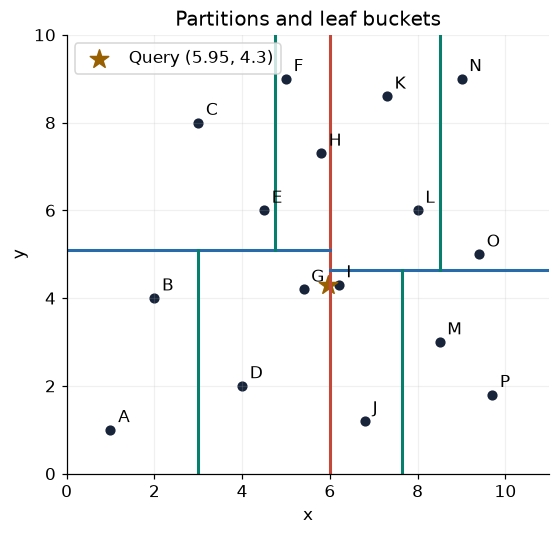

In [18]:
def draw_partitions(node,ax,depth=0):
    if 'left' not in node:return
    bounds,cut,axis=node['bounds'],node['cut'],node['axis']
    color=[RUST,BLUE,GREEN][depth%3]
    if axis==0:ax.plot([cut,cut],bounds[1],color=color,lw=2)
    else:ax.plot(bounds[0],[cut,cut],color=color,lw=2)
    draw_partitions(node['left'],ax,depth+1);draw_partitions(node['right'],ax,depth+1)

fig,ax=plt.subplots(figsize=(7,5))
draw_partitions(kd_root,ax)
ax.scatter(*KD_POINTS.T,c='#172439',s=32)
for name,point in zip(KD_IDS,KD_POINTS):ax.annotate(name,point,xytext=(5,5),textcoords='offset points')
ax.scatter(*KD_QUERY,c=GOLD,marker='*',s=160,label='Query (5.95, 4.3)')
ax.set(xlim=(0,11),ylim=(0,10),xlabel='x',ylabel='y',title='Partitions and leaf buckets')
ax.set_aspect('equal');ax.legend(loc='upper left');fig.tight_layout();plt.show()

## 7. Searching the first leaf is only the start

The query lies just to the left of the root cut x = 6. Its true nearest point,
I, lies to the right. We must revisit other regions if they could improve the
current answer.

For any rectangular region R, compute the smallest possible distance from the
query to R. If that lower bound exceeds the current best distance, every point
inside R is too far away and we can prune the region. For k neighbors, use the
distance to the farthest of the current k candidates. Before k candidates have
been collected, there is no finite pruning radius.

In [19]:
def box_distance(query, bounds):
    """Minimum Euclidean distance from query to any point in a rectangle."""
    delta = np.maximum(np.maximum(bounds[:, 0]-query, query-bounds[:, 1]), 0)
    return float(np.linalg.norm(delta))


def query_kd(points, tree, query, k=1):
    """Exact search: inspect near regions first, prune using a distance bound."""
    query = np.asarray(query, dtype=float)
    best, trace = [], []
    def visit(node, path='root'):
        lower = box_distance(query, node['bounds'])
        radius = best[-1][0] if len(best) == k else float('inf')
        # Strict > preserves tied candidates. Distance then index breaks ties.
        if lower > radius + 1e-12:
            trace.append(dict(event='prune', path=path, lower=lower, radius=radius))
            return
        trace.append(dict(event='visit', path=path, lower=lower, radius=radius))
        if 'left' not in node:
            for i in node['ids']:
                distance = float(np.linalg.norm(points[i]-query))
                best.append((distance, i))
                best.sort()
                del best[k:]
                trace.append(dict(event='distance', path=path, id=i, distance=distance,
                                  best=[(d,j) for d,j in best]))
        else:
            near, far = ('left', 'right') if query[node['axis']] < node['cut'] else ('right', 'left')
            visit(node[near], path+'/'+near)
            visit(node[far], path+'/'+far)
    visit(tree)
    return best, trace

In [20]:
K=1
answer,trace=query_kd(KD_POINTS,kd_root,KD_QUERY,k=K)
for event in trace:
    if event['event']=='distance':
        print(f"Check {KD_IDS[event['id']]}: distance {event['distance']:.3f}")
    elif event['event']=='prune':
        print(f"Prune {event['path']}: lower bound {event['lower']:.3f} > radius {event['radius']:.3f}")
    else:
        print('Visit',event['path'])
print('Answer:',[(KD_IDS[i],round(d,3)) for d,i in answer])
print('Point distances computed:',sum(e['event']=='distance' for e in trace),'of',len(KD_POINTS))

Visit root
Visit root/left
Visit root/left/left
Visit root/left/left/right
Check D: distance 3.015
Check G: distance 0.559
Prune root/left/left/left: lower bound 2.950 > radius 0.559
Prune root/left/right: lower bound 0.800 > radius 0.559
Visit root/right
Visit root/right/left
Visit root/right/left/left
Check I: distance 0.250
Check J: distance 3.214
Prune root/right/left/right: lower bound 1.700 > radius 0.250
Prune root/right/right: lower bound 0.354 > radius 0.250
Answer: [('I', 0.25)]
Point distances computed: 4 of 16


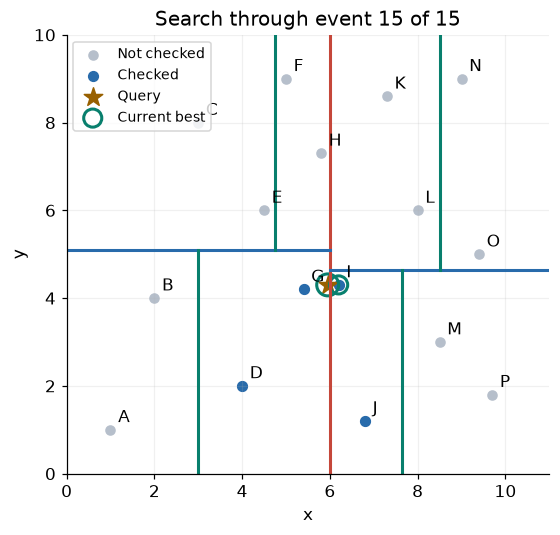

In [21]:
STEP=len(trace)-1                 # Try 0, 5, 9, or another event index.
shown=trace[:STEP+1]
tested=[e['id'] for e in shown if e['event']=='distance']
current=sorted((float(np.linalg.norm(KD_POINTS[i]-KD_QUERY)),i) for i in tested)[:K]
fig,ax=plt.subplots(figsize=(7,5))
draw_partitions(kd_root,ax)
ax.scatter(*KD_POINTS.T,c='#b6bfcb',s=35,label='Not checked')
if tested: ax.scatter(*KD_POINTS[tested].T,c=BLUE,s=40,label='Checked')
for name,point in zip(KD_IDS,KD_POINTS):ax.annotate(name,point,xytext=(5,5),textcoords='offset points')
ax.scatter(*KD_QUERY,c=GOLD,marker='*',s=160,label='Query')
if len(current)==K:
    radius=current[-1][0]
    ax.add_patch(plt.Circle(KD_QUERY,radius,fill=False,color=GREEN,lw=2))
    candidates=[i for d,i in current]
    ax.scatter(*KD_POINTS[candidates].T,facecolors='none',edgecolors=GREEN,s=140,lw=2,label='Current best')
ax.set(xlim=(0,11),ylim=(0,10),xlabel='x',ylabel='y',title=f'Search through event {STEP+1} of {len(trace)}')
ax.set_aspect('equal');ax.legend(loc='upper left',fontsize=9);fig.tight_layout();plt.show()

In [22]:
def verify_kd():
    bounds = np.array([[0,11],[0,10]], dtype=float)
    tree = build_kd(KD_POINTS, bounds=bounds)
    rng = np.random.default_rng(SEED)
    queries = np.vstack([KD_QUERY, KD_POINTS, [[6,5],[0,0],[11,10]], rng.uniform(-1,12,(100,2))])
    for query in queries:
        for k in [1,3,5,16]:
            answer, _ = query_kd(KD_POINTS, tree, query, k)
            expected = sorted((float(np.linalg.norm(p-query)),i) for i,p in enumerate(KD_POINTS))[:k]
            assert [i for _,i in answer] == [i for _,i in expected]
            assert np.allclose([d for d,_ in answer], [d for d,_ in expected])
    # Explicit tie and duplicate checks exercise equality at a partition.
    ties = np.array([[0,0],[0,0],[1,0],[-1,0]], dtype=float)
    tied_tree = build_kd(ties, leaf_size=1)
    for k in [1,2,3,4]:
        answer, _ = query_kd(ties, tied_tree, np.array([0,0]), k)
        assert answer == sorted((float(np.linalg.norm(p)),i) for i,p in enumerate(ties))[:k]
    answer, trace = query_kd(KD_POINTS, tree, KD_QUERY)
    assert answer[0][1] == 8 and abs(answer[0][0]-0.25)<1e-12
    assert any(t['event']=='prune' for t in trace)
    return dict(points=KD_POINTS.tolist(), ids=KD_IDS, query=KD_QUERY.tolist(),
                answer=[dict(id=KD_IDS[i], distance=d) for d,i in answer],
                distance_calls=sum(t['event']=='distance' for t in trace),
                pruned_regions=sum(t['event']=='prune' for t in trace), verified_queries=len(queries)*4+4)

In [23]:
verification=verify_kd()
print('Verified',verification['verified_queries'],'query/k cases against exhaustive search, including ties and duplicates.')
assert verification['answer'][0]['id']=='I'
assert abs(verification['answer'][0]['distance']-.25)<1e-12
print('For the lecture query:',verification['distance_calls'],'point comparisons and',verification['pruned_regions'],'pruned regions.')

Verified 484 query/k cases against exhaustive search, including ties and duplicates.
For the lecture query: 4 point comparisons and 4 pruned regions.


**Reflection:** why does a balanced tree not guarantee that nearest-neighbor
search follows only one root-to-leaf path?

<details><summary>Instructor reference</summary>
Balancing controls the depth of a path. A nearest-neighbor query may still need
several paths because a nearby point can lie across a cut. The distance bounds,
not the tree height alone, determine how many regions can be excluded. In the
example, G is the first useful candidate on the left, but I on the right is closer.
</details>

**Exercise:** change the query to a stored point, then a point on a cut. Try k = 3.
Explain why the circle uses the farthest retained candidate's distance. The search
uses strict `>` when pruning, so it does not discard an equal-distance candidate.

## 8. What the index costs, and what dimension changes

A full scan computes a distance to every stored point. For n vectors with d
coordinates, its distance arithmetic is proportional to n times d. A tree first
pays for construction and additional storage. That preparation can be reused
across many queries.

The following benchmark uses the same stored vectors and queries for both
methods. The full scan is vectorized NumPy, not a slow Python loop. It selects
the five smallest distances without fully sorting all candidates. The kd-tree is
scikit-learn's optimized implementation, with leaf size 30. Both are exact.

The data are full-dimensional Gaussian clouds, chosen to expose how pruning can
weaken with dimension. Real datasets may have much lower intrinsic dimension.
Do not read these times as a universal cutoff or a logarithmic-time guarantee.

In [24]:
def brute_neighbors(X, Q, k=5):
    """Vectorized exact scan, with top-k selection rather than a full sort."""
    squared = np.maximum(np.sum(Q*Q, axis=1)[:,None] + np.sum(X*X, axis=1)[None,:] - 2*(Q@X.T), 0)
    ids = np.argpartition(squared, k-1, axis=1)[:,:k]
    distances = np.take_along_axis(squared, ids, axis=1)
    order = np.argsort(distances, axis=1)
    return np.sqrt(np.take_along_axis(distances, order, axis=1)), np.take_along_axis(ids, order, axis=1)


def benchmark_search(n=3000, nq=100, repetitions=5):
    """Measured on isotropic Gaussian vectors; no universal speed claim."""
    rows = []
    with threadpool_limits(limits=1):
        for dimension in [2,10,50,300]:
            rng = np.random.default_rng(SEED+dimension)
            X, Q = rng.normal(size=(n,dimension)), rng.normal(size=(nq,dimension))
            builds=[]
            for _ in range(repetitions):
                start=time.perf_counter(); tree=KDTree(X,leaf_size=30); builds.append(time.perf_counter()-start)
            # Warm up both implementations before timing repeated queries.
            expected, _ = brute_neighbors(X,Q)
            got, _ = tree.query(Q,k=5)
            assert np.allclose(expected,got,rtol=1e-7,atol=1e-7)
            brute_times, kd_times = [], []
            for rep in range(repetitions):
                methods = ['brute','kd'] if rep%2==0 else ['kd','brute']
                for method in methods:
                    start=time.perf_counter()
                    if method=='brute': brute_neighbors(X,Q)
                    else:
                        tree.reset_n_calls(); tree.query(Q,k=5)
                    (brute_times if method=='brute' else kd_times).append(time.perf_counter()-start)
            # get_arrays includes the stored data, index array, node data and bounds.
            arrays=tree.get_arrays()
            rows.append(dict(dimension=dimension,n=n,queries=nq,k=5,
                build_ms=float(1000*np.median(builds)),
                brute_query_ms=float(1000*np.median(brute_times)),
                kd_query_ms=float(1000*np.median(kd_times)),
                vector_bytes=int(X.nbytes), index_extra_bytes=int(sum(a.nbytes for a in arrays[1:])),
                kd_calls=int(tree.get_n_calls()), brute_calls=n*nq,
                repetitions=repetitions))
    return rows

Median of 5 warmed-up repetitions; one BLAS thread; 3,000 points, 100 queries, k=5.
 dim   build ms   scan ms    kd ms    point distances checked by kd
   2      0.465     3.130     0.179      7640 / 300000
  10      1.449     4.032     2.128    221620 / 300000
  50      6.658     3.913     7.989    300000 / 300000
 300     36.538     8.032    46.521    300000 / 300000


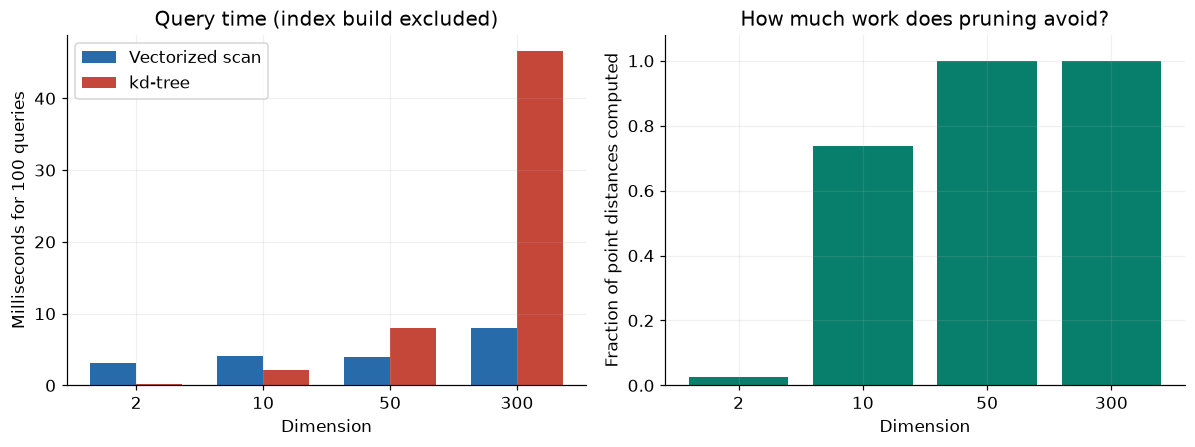

Array storage only; MB = 1,000,000 bytes. Python/process overhead is excluded.
d=  2: vectors 0.048 MB; extra index arrays 0.032 MB
d= 10: vectors 0.240 MB; extra index arrays 0.048 MB
d= 50: vectors 1.200 MB; extra index arrays 0.130 MB
d=300: vectors 7.200 MB; extra index arrays 0.638 MB


In [25]:
benchmarks=benchmark_search()
print('Median of 5 warmed-up repetitions; one BLAS thread; 3,000 points, 100 queries, k=5.')
print(' dim   build ms   scan ms    kd ms    point distances checked by kd')
for r in benchmarks:
    print(f"{r['dimension']:4d} {r['build_ms']:10.3f} {r['brute_query_ms']:9.3f} {r['kd_query_ms']:9.3f} {r['kd_calls']:9d} / {r['brute_calls']}")
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
dims=[r['dimension'] for r in benchmarks]
positions=np.arange(len(dims))
axes[0].bar(positions-.18,[r['brute_query_ms'] for r in benchmarks],width=.36,color=BLUE,label='Vectorized scan')
axes[0].bar(positions+.18,[r['kd_query_ms'] for r in benchmarks],width=.36,color=RUST,label='kd-tree')
axes[0].set(xticks=positions,xticklabels=dims,xlabel='Dimension',ylabel='Milliseconds for 100 queries',title='Query time (index build excluded)');axes[0].legend()
axes[1].bar(positions,[r['kd_calls']/r['brute_calls'] for r in benchmarks],color=GREEN)
axes[1].set(xticks=positions,xticklabels=dims,xlabel='Dimension',ylabel='Fraction of point distances computed',ylim=(0,1.08),title='How much work does pruning avoid?')
fig.tight_layout();plt.show()
print('Array storage only; MB = 1,000,000 bytes. Python/process overhead is excluded.')
for r in benchmarks:
    print(f"d={r['dimension']:3d}: vectors {r['vector_bytes']/1e6:.3f} MB; extra index arrays {r['index_extra_bytes']/1e6:.3f} MB")

A kd-tree can inspect almost all points in high dimension and still pay its
traversal overhead. A vectorized full scan can therefore be competitive or faster.
The appropriate method depends on the data, metric, number of queries, memory,
and implementation.

Preparation has two different meanings here:

- **Representation:** choose features, normalize or scale as appropriate, and
  apply the same transformation to stored rows and queries.
- **Index construction:** organize the resulting vectors for repeated searches.
  Changing the representation generally requires rebuilding the corresponding
  index. Adding catalog entries requires maintaining or rebuilding the index
  according to the data structure's capabilities.

These concerns apply both to word embeddings and to audio embeddings. A chosen
representation determines what “near” means before a search structure accelerates
the comparison.

## 9. A small connection to random projections

Unit II examined whether a random projection preserves distances and nearest
words. Below we compare exact neighbor lists in the original 300-dimensional
space with lists computed after projection. Projection is one way to change the
cost and fidelity of retrieval. It is not the same as an approximate-search
index: an approximate index can search the original representation while choosing
not to inspect every potentially relevant candidate.

We measure **recall at 5**: what fraction of the original five nearest neighbors
are recovered? Do not confuse this retrieval measure with classification recall.

In [26]:
original=np.array(word_data['vectors300'],dtype=np.float64)
original/=np.linalg.norm(original,axis=1,keepdims=True)
def all_neighbors(vectors,k=5):
    distances=np.maximum(np.sum(vectors*vectors,axis=1)[:,None]+np.sum(vectors*vectors,axis=1)[None,:]-2*vectors@vectors.T,0)
    np.fill_diagonal(distances,np.inf)
    return np.argsort(distances,axis=1)[:,:k]
reference_neighbors=all_neighbors(original)
projection_rng=np.random.default_rng(SEED)
for dimension in [10,30,100]:
    R=projection_rng.normal(size=(300,dimension))/np.sqrt(dimension)
    projected=original@R
    approximate_neighbors=all_neighbors(projected)
    recall=np.mean([len(set(a)&set(b))/5 for a,b in zip(reference_neighbors,approximate_neighbors)])
    print(f'{dimension:3d} projected coordinates: mean recall at 5 = {recall:.3f}')

 10 projected coordinates: mean recall at 5 = 0.277
 30 projected coordinates: mean recall at 5 = 0.507
100 projected coordinates: mean recall at 5 = 0.712


## 10. Which remembered values should contribute most?

Uniform kNN gives every retrieved neighbor equal influence. Distance weighting
gives closer neighbors more influence. The code below compares these choices
with k held fixed, using the same training and validation data.

This motivates a broader question: if relevance varies continuously, how should
we convert relevance scores into weights and combine the remembered values?

Uniform weights, k=11: validation MSE 0.09993
Distance weights, k=11: validation MSE 0.10605


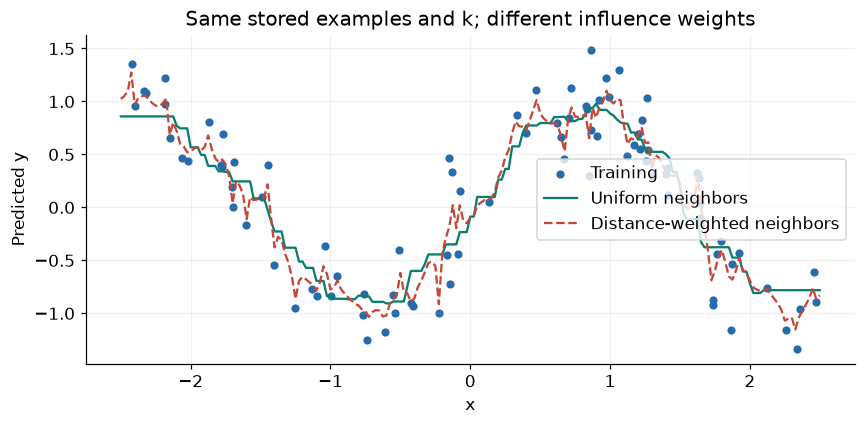

In [27]:
K=11
uniform=next(r for r in regression['snapshots'] if r['k']==K)
weighted=regression['weighted']
print(f'Uniform weights, k={K}: validation MSE {uniform["valid_mse"]:.5f}')
print(f'Distance weights, k={K}: validation MSE {weighted["valid_mse"]:.5f}')
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(regression['train']['X'],regression['train']['y'],c=BLUE,s=19,label='Training')
ax.plot(regression['grid'],uniform['prediction'],color=GREEN,label='Uniform neighbors')
ax.plot(regression['grid'],weighted['prediction'],'--',color=RUST,label='Distance-weighted neighbors')
ax.set(xlabel='x',ylabel='Predicted y',title='Same stored examples and k; different influence weights')
ax.legend();fig.tight_layout();plt.show()

### Review

1. What is the query in Shazam? What is stored in the searchable catalog?
2. Why does the word-vector search divide each row by its length?
3. How does a list of nearest neighbors become a regression prediction?
4. Why is kNN non-parametric even though k is a chosen setting?
5. What fact permits a kd-tree search to discard a region safely?
6. Why might the tree lose to a full scan for 300-dimensional vectors?
7. Which data should choose k and preprocessing, and which should remain reserved?

<details><summary>Instructor reference answers</summary>

1. The query is an observed audio fragment, represented by an acoustic signature.
   Stored signatures are associated with recording identities and metadata.
2. Unit normalization makes the dot product equal cosine similarity.
3. Average the stored neighbors' target values, or form a weighted average.
4. Its predictive state includes stored examples and can grow with the dataset.
   k is a hyperparameter; non-parametric does not mean no choices.
5. A valid lower bound on every point's distance in that region exceeds the
   current kth-neighbor distance. Ties must follow the specified policy.
6. Many regions can remain plausible, so pruning saves little while traversal
   adds overhead. The full scan can use efficient vectorized computation.
7. Fit transformations on the training data. Use validation to compare the stated
   choices. Reserve test data for a final evaluation after those choices are fixed.

</details>

### Sources and reproducibility

- [GloVe, Stanford NLP](https://nlp.stanford.edu/projects/glove/), Pennington,
  Socher, and Manning, 2014. The embedded vectors come from the course's existing
  float16 files and are converted to float32. License:
  [Public Domain Dedication and License v1.0](https://opendatacommons.org/licenses/pddl/1-0/).
- [Wang, 2003, audio fingerprinting](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf).
- [Apple ShazamKit](https://developer.apple.com/documentation/shazamkit).
- [Chang et al., 2021, neural audio fingerprints](https://arxiv.org/abs/2010.11910).
- [scikit-learn nearest neighbors](https://scikit-learn.org/stable/modules/neighbors.html).

All non-word datasets are synthetic. Seed 23 fixes the displayed data and
experiments. Timings vary by hardware and software. Prediction figures use
computed model results. All exact-search checks run when this notebook executes.
No reserved test score selects a model or appears in this notebook.